Linear regression from scratch using numpys, pandas and matplotlib


##VISUALISING THE DATA

,price,area,bedrooms,bathrooms,stories,mainroad,guestroom,basement,hotwaterheating,airconditioning,parking,prefarea,furnishingstatus
0,13300000,7420,4,2,3,yes,no,no,no,yes,2,yes,furnished
1,12250000,8960,4,4,4,yes,no,no,no,yes,3,no,furnished
2,12250000,9960,3,2,2,yes,no,yes,no,no,2,yes,semi-furnished
3,12215000,7500,4,2,2,yes,no,yes,no,yes,3,yes,furnished
4,11410000,7420,4,1,2,yes,yes,yes,no,yes,2,no,furnished
...,...,...,...,...,...,...,...,...,...,...,...,...,...
540,1820000,3000,2,1,1,yes,no,yes,no,no,2,no,unfurnished
541,1767150,2400,3,1,1,no,no,no,no,no,0,no,semi-furnished
542,1750000,3620,2,1,1,yes,no,no,no,no,0,no,unfurnished
543,1750000,2910,3,1,1,no,no,no,no,no,0,no,furnished


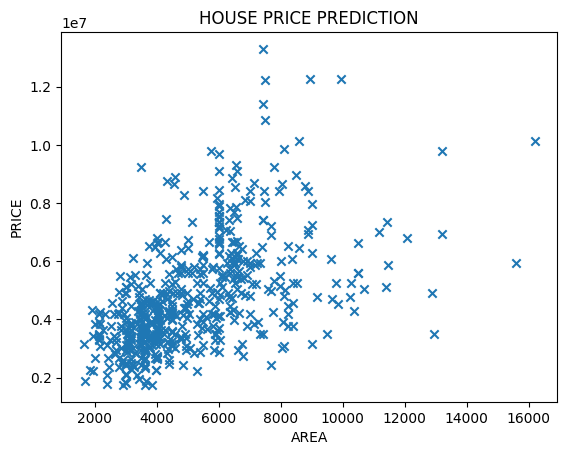

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

dataset = pd.read_csv("Housing.csv")
x_train = np.array(dataset["area"])
y_train=np.array(dataset["price"])


plt.title("HOUSE PRICE PREDICTION")
plt.xlabel("AREA")
plt.ylabel("PRICE")

plt.scatter(x_train,y_train,marker="x")


##COST FUNCTION


In [6]:
def compute_cost(w,b,x,y):
    m = x.shape[0]
    cost_sum =0 
    for i in range(m):
        f_wb = w * x[i] + b
        cost = (f_wb - y[i])**2
        cost_sum+=cost

    total_cost = (1 / (2 * m)) * cost_sum 

    return total_cost

##GRADIENT FUNCTION

In [7]:
def compute_gradient(x,y,w,b):
    m = x.shape[0]
    dj_dw = 0
    dj_db = 0
    for i in range(m):  
        f_wb = w * x[i] + b 
        dj_dw_i = (f_wb - y[i]) * x[i] 
        dj_db_i = f_wb - y[i] 
        dj_db += dj_db_i
        dj_dw += dj_dw_i 
    dj_dw = dj_dw / m 
    dj_db = dj_db / m
    return dj_dw, dj_db

In [8]:
def gradient_descent(x, y, w_in, b_in, alpha, num_iters, gradient_function): 

    w=w_in
    b=b_in

    for i in range(num_iters):
        dj_dw , dj_db = gradient_function(x,y,w,b)
        b = b - alpha * dj_db                            
        w = w - alpha * dj_dw 

        

    return w,b



##RUNNING THE FINAL GRADIENT DESCENT

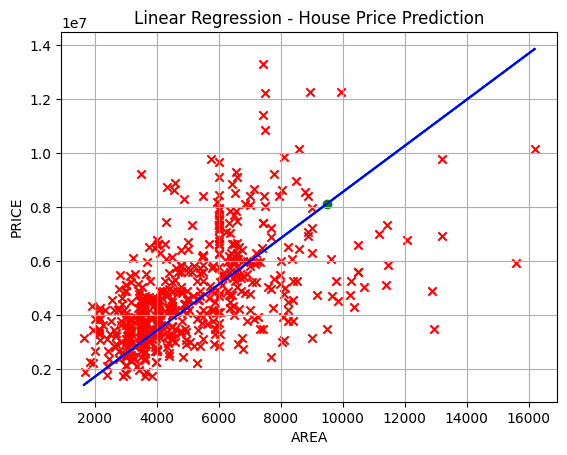

Predicted price for area 9500m^2: $8129234.277216332


In [ ]:
w_fin , b_fin = gradient_descent(x_train,y_train,0,0,0.00000001,5000,compute_gradient)

plt.title("Linear Regression - House Price Prediction")
plt.xlabel("AREA")
plt.ylabel("PRICE")
plt.scatter(x_train,y_train,marker="x",color="red")
plt.plot(x_train,x_train*w_fin + b_fin)

#sample data 
area = 9500
cost = area*w_fin+b_fin

plt.scatter(area,cost,marker="o",color="green")


plt.grid()
plt.show()
print(f"Predicted price for area {area}m^2: ${cost}")